# Proyecto final IA: ¿Esta llamada de venta se va a cerrar?

**Autor:** Juan Fernando Ordoñez Martinez

**Problema:** trabajo como closer de ventas por llamada. Quise ver si un modelo de IA puede
predecir, con los datos de un cliente, si va a comprar o no **antes** de llamarlo.
Así el vendedor puede priorizar a quién llamar primero.

**Dataset:** Bank Marketing (UCI Machine Learning Repository). Son 45.211 llamadas reales de
campañas de venta telefónica de un banco portugués. La columna objetivo `y` dice si el cliente
compró el producto (un depósito a plazo) o no.

**Tipo de problema:** clasificación binaria (compra sí / compra no), igual que el ejercicio de diabetes.

**Lo que se usa del curso:**
- Ciencia de datos: limpieza, diagramas de cajas, matriz de correlación (primer corte)
- Random Forest + búsqueda de hiperparámetros con validación cruzada (primer corte)
- Red neuronal artificial (ANN) con Keras, Dropout y Early Stopping (segundo corte)
- Métricas de clasificación: matriz de confusión, precision, recall, F1 (segundo corte)
- Despliegue del modelo en una página web con Streamlit (parcial del segundo corte)

## 1. Importar las librerías

In [1]:
# Manipulación de datos
import pandas as pd
# Operaciones numéricas
import numpy as np
# Para medir tiempos de entrenamiento
from time import time
# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Partición de datos y búsqueda de hiperparámetros
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
# Modelo de Machine Learning
from sklearn.ensemble import RandomForestClassifier
# Escalado (lo necesita la red neuronal)
from sklearn.preprocessing import StandardScaler
# Métricas
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report)

# Deep Learning
from tensorflow import keras
from tensorflow.keras import layers

# Para guardar el modelo y usarlo en la página web
import joblib

# Semillas: así siempre salen los mismos resultados
np.random.seed(42)
keras.utils.set_random_seed(42)

I0000 00:00:1795390471.794787    2761 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795390471.832594    2761 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795390472.896415    2761 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 2. Cargar el dataset

El archivo `bank-full.csv` viene dentro del zip de la UCI (`bank+marketing.zip` > `bank.zip`).
Igual que en el parcial del primer corte, el separador **no** es la coma sino el punto y coma `;`.

En Colab: súbelo a tu Drive y cambia la ruta, o súbelo directo a la sesión.

In [2]:
# from google.colab import drive
# drive.mount('/content/drive')
RUTA = 'bank-full.csv'   # cambiar si está en otra carpeta del Drive

df = pd.read_csv(RUTA, sep=';')
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


### ¿Qué significa cada columna?

| Columna | Significado |
|---|---|
| age | edad |
| job | tipo de trabajo |
| marital | estado civil |
| education | nivel educativo |
| default | ¿tiene créditos en mora? |
| balance | saldo promedio anual en el banco (euros) |
| housing | ¿tiene crédito de vivienda? |
| loan | ¿tiene crédito personal? |
| contact | por dónde se le contactó (celular / fijo) |
| day, month | día y mes del último contacto |
| duration | duración de la llamada en segundos |
| campaign | cuántas veces se le llamó en esta campaña |
| pdays | días desde que se le contactó en la campaña anterior (-1 = nunca) |
| previous | cuántas veces se le contactó antes de esta campaña |
| poutcome | cómo terminó la campaña anterior |
| **y** | **¿compró? (yes / no)**  <- lo que queremos predecir |

## 3. Exploración inicial de los datos (EDA)

In [4]:
# Estadísticas de las columnas numéricas
display(df.describe())

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


y
no     39922
yes     5289
Name: count, dtype: int64

Porcentaje que compró: 11.7 %


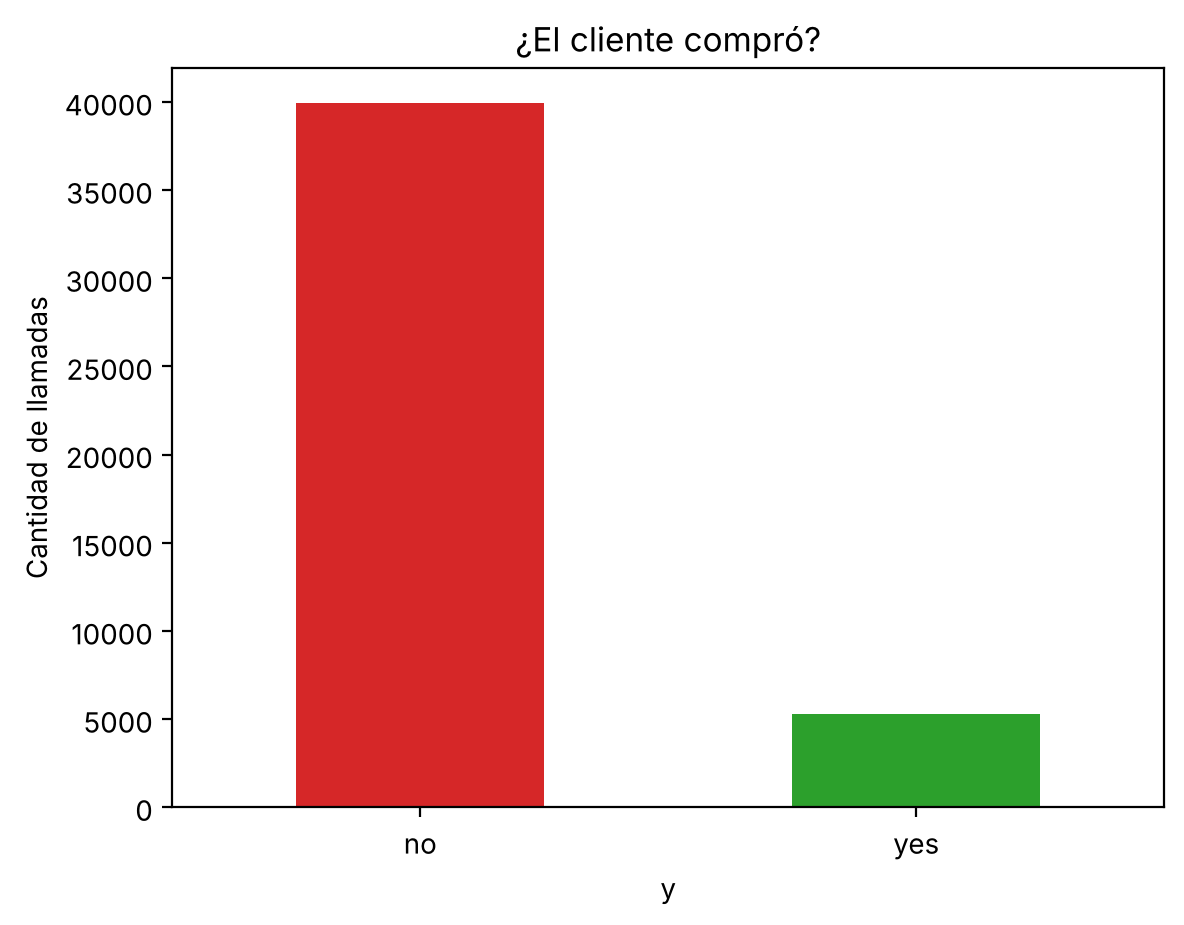

In [5]:
# ¿Cuántos compraron y cuántos no?
conteo = df['y'].value_counts()
print(conteo)
print()
print('Porcentaje que compró:', round(conteo['yes'] / len(df) * 100, 2), '%')

conteo.plot(kind='bar', color=['tab:red', 'tab:green'])
plt.title('¿El cliente compró?')
plt.ylabel('Cantidad de llamadas')
plt.xticks(rotation=0)
plt.show()

**Observación importante:** solo alrededor del 12% de las llamadas terminan en venta.
El dataset está **desbalanceado**. Eso tiene una consecuencia directa: un "modelo" que
siempre diga *"no va a comprar"* tendría un accuracy cercano al 88% sin haber aprendido nada.
Por eso en este proyecto **el accuracy no es la métrica principal**: nos fijamos en
**recall**, **precision** y **F1** de la clase "sí compra".

## Diagramas de cajas (BOXPLOT)

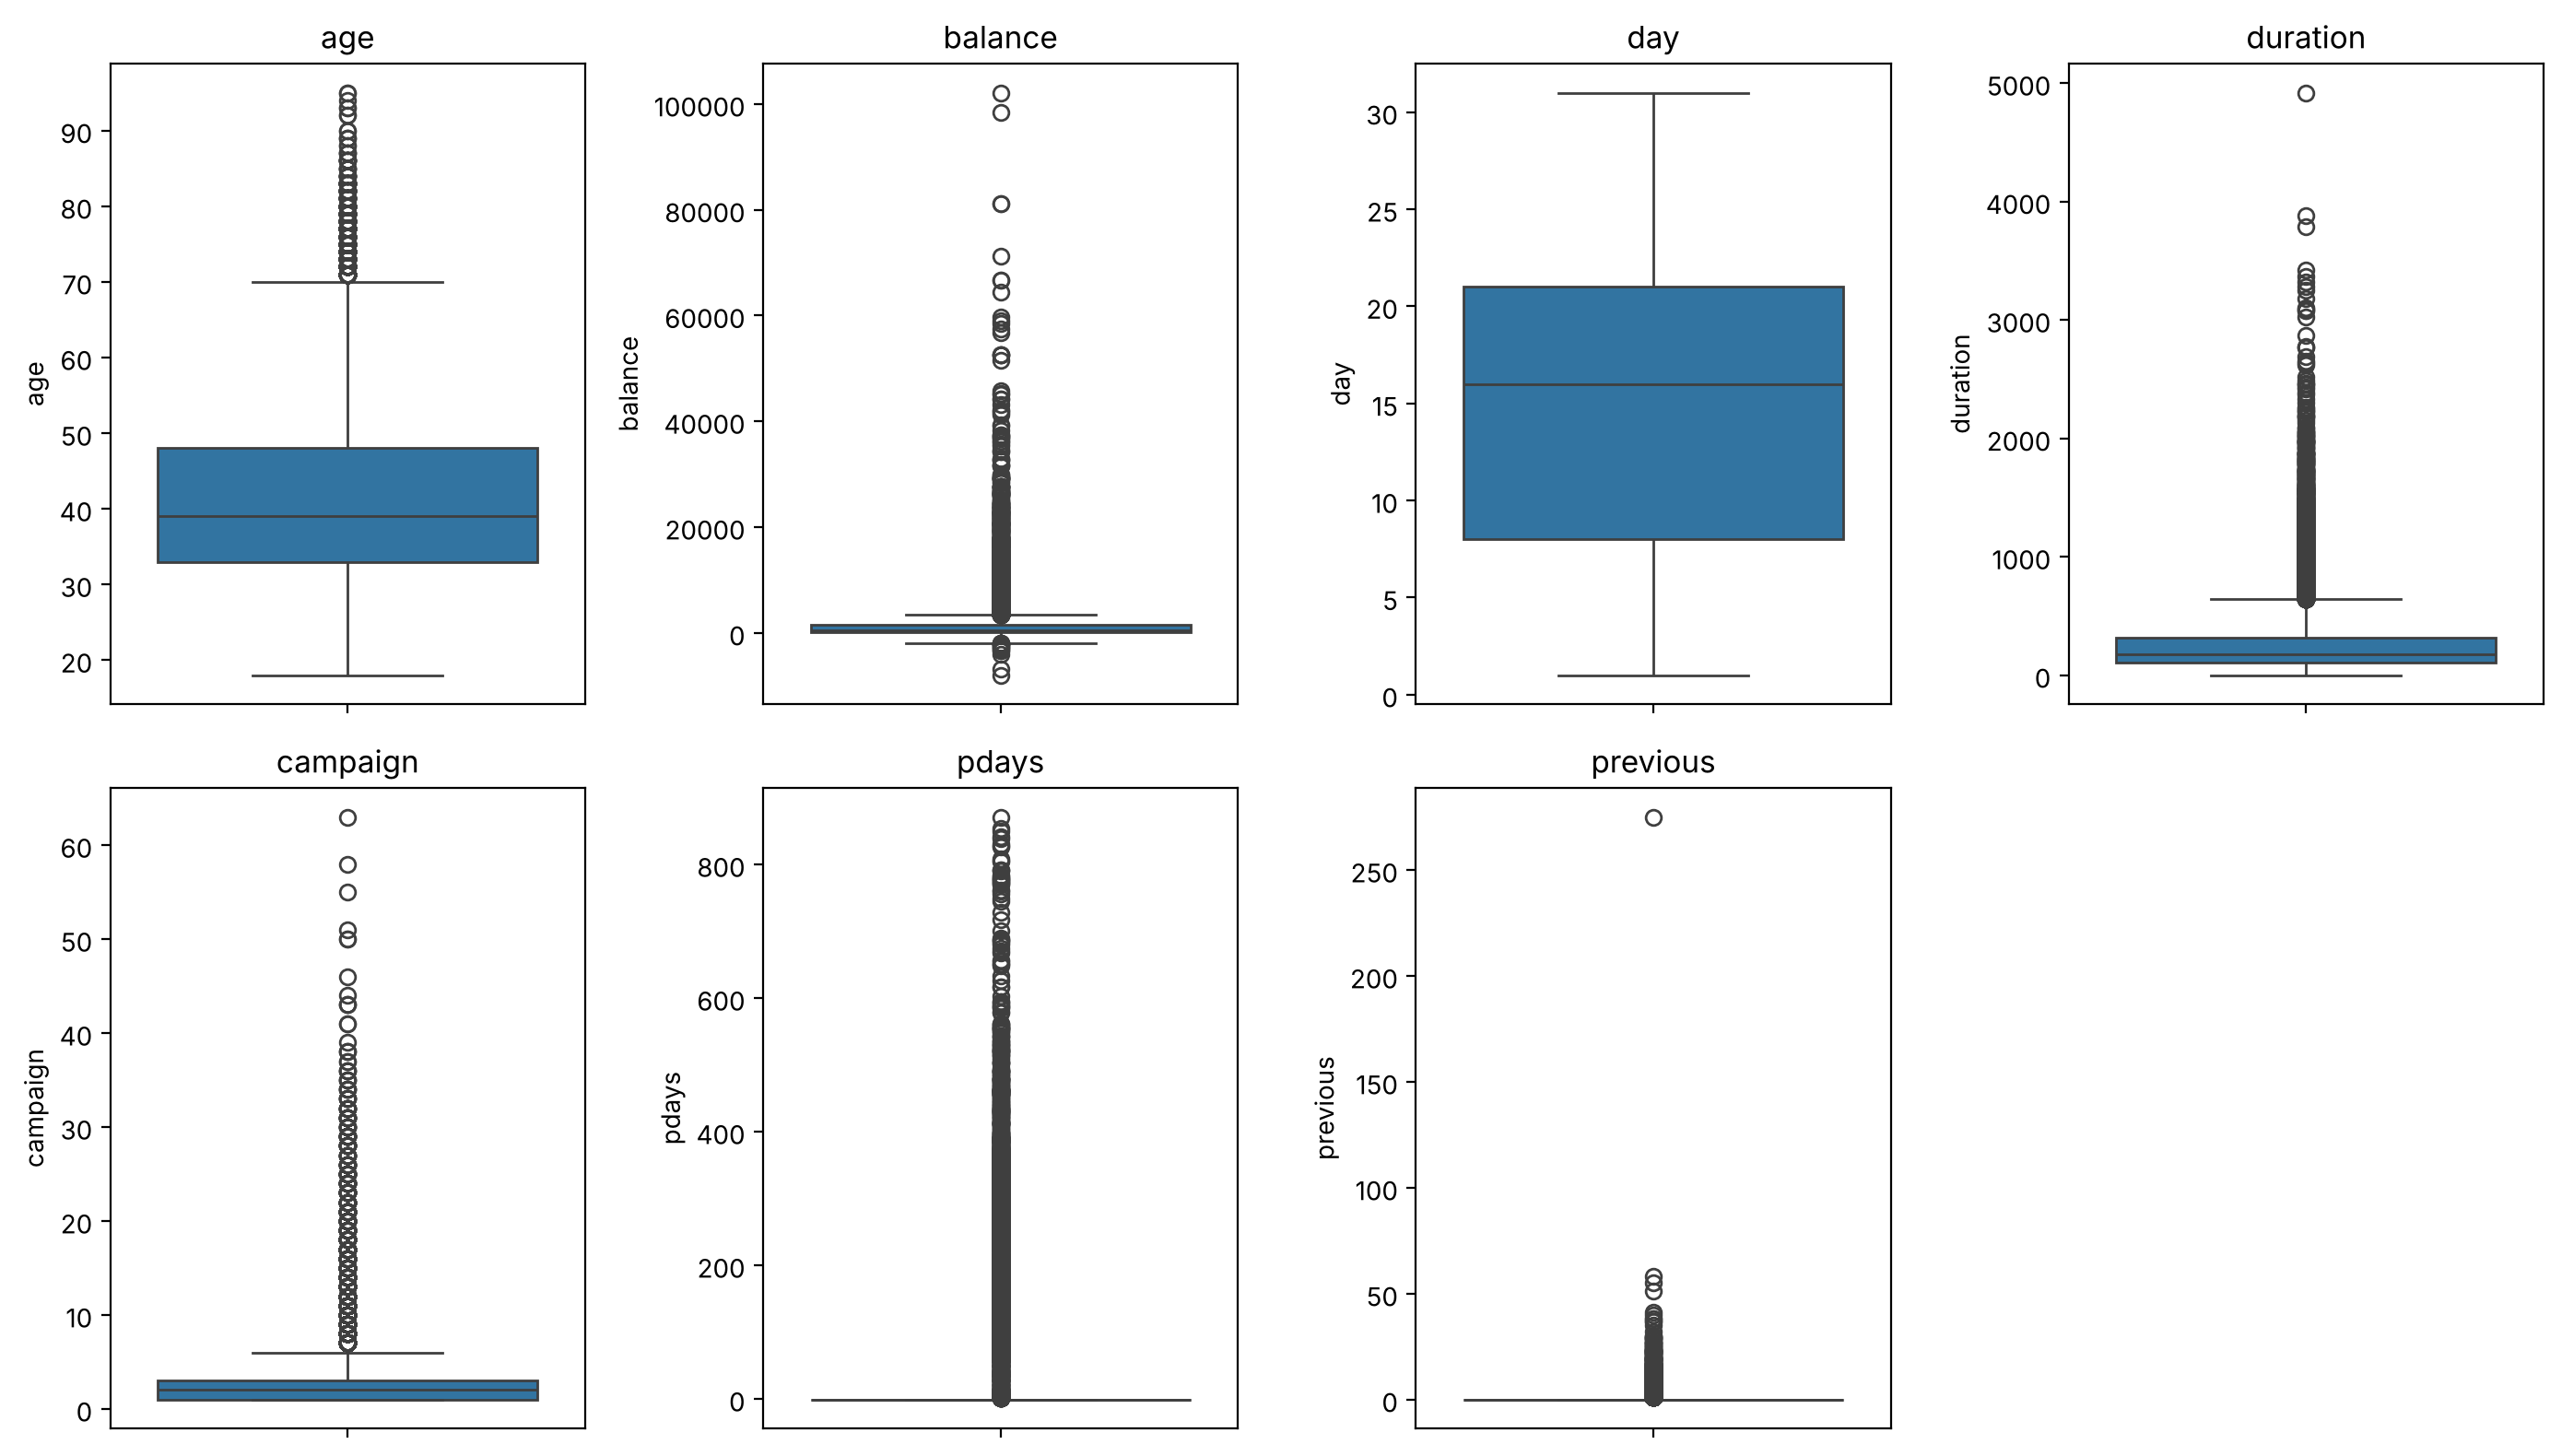

In [6]:
columnas_numericas = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

plt.figure(figsize=(14, 8))
for i, col in enumerate(columnas_numericas):
    plt.subplot(2, 4, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

Hay muchos valores atípicos en `balance`, `campaign`, `pdays` y `previous`.
**No los eliminamos:** no son errores de registro, son clientes reales (alguien con mucho
dinero en el banco, o alguien a quien llamaron muchas veces). Además Random Forest es robusto
frente a valores atípicos, como se vio en el parcial del primer corte.

## Matriz de correlación

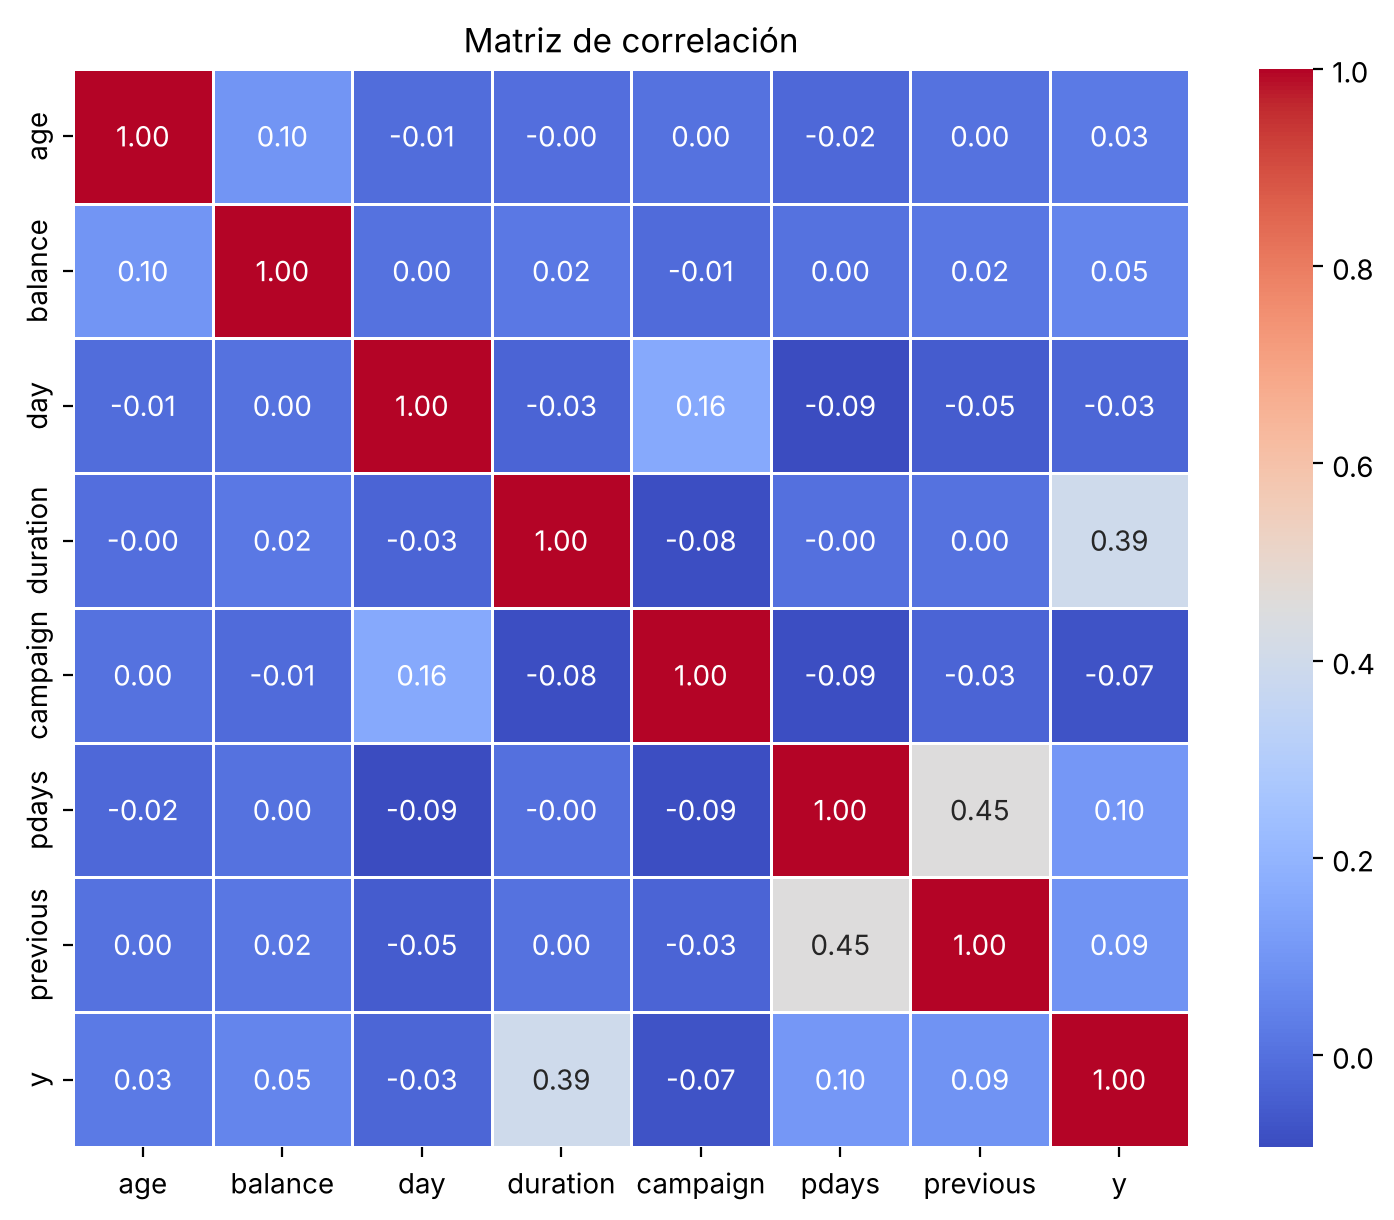

Correlación de cada variable con la compra (y):
y           1.000000
duration    0.394521
pdays       0.103621
previous    0.093236
balance     0.052838
age         0.025155
day        -0.028348
campaign   -0.073172
Name: y, dtype: float64


In [7]:
# Pasamos 'y' a número para poder correlacionarla: yes -> 1, no -> 0
df_corr = df[columnas_numericas].copy()
df_corr['y'] = df['y'].map({'yes': 1, 'no': 0})

plt.figure(figsize=(9, 7))
matriz_correlacion = df_corr.corr()
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriz de correlación')
plt.show()

print('Correlación de cada variable con la compra (y):')
print(matriz_correlacion['y'].sort_values(ascending=False))

## 4. Limpieza y preparación

### 4.1 Quitamos la columna `duration` (fuga de información)

En la matriz de correlación, `duration` es por lejos la variable más relacionada con la compra.
**Pero no se puede usar:** la duración de la llamada solo se conoce cuando la llamada ya terminó,
y en ese momento ya se sabe si el cliente compró o no. Si la dejamos, el modelo "hace trampa":
saca un puntaje muy alto en las pruebas pero en la vida real no sirve, porque queremos predecir
**antes** de llamar.

La propia documentación del dataset (archivo `bank-additional-names.txt`, dentro del mismo zip de la UCI)
dice que esta variable solo debe usarse como referencia y que hay que descartarla si se quiere un
modelo predictivo realista.

In [8]:
df = df.drop(columns=['duration'])
df.shape

(45211, 16)

### 4.2 Valores faltantes

El dataset no tiene celdas vacías (NaN), pero algunas columnas de texto usan la palabra
`unknown` cuando no se tiene el dato. La dejamos como una categoría más: el hecho de no
conocer el dato también puede ser información (por ejemplo, en `poutcome`, `unknown`
significa que el cliente nunca estuvo en una campaña anterior).

In [9]:
print('Celdas vacías:', df.isna().sum().sum())
print()
columnas_texto = ['job', 'marital', 'education', 'default', 'housing',
                  'loan', 'contact', 'month', 'poutcome']
for col in columnas_texto:
    n = (df[col] == 'unknown').sum()
    if n > 0:
        print(f'{col}: {n} valores unknown ({round(n / len(df) * 100, 1)}%)')

Celdas vacías: 0

job: 288 valores unknown (0.6%)
education: 1857 valores unknown (4.1%)
contact: 13020 valores unknown (28.8%)
poutcome: 36959 valores unknown (81.7%)


### 4.3 Convertir texto a números (One-Hot Encoding)

Los modelos solo entienden números. Columnas como `job` tienen texto (`admin.`, `student`...).
Con `pd.get_dummies` cada categoría se vuelve su propia columna de 0 y 1.
Ejemplo: `marital` se vuelve `marital_married`, `marital_single`, etc.

No asignamos números tipo 1, 2, 3 a las categorías porque el modelo creería que
"divorciado < casado < soltero", y ese orden no existe.

In [10]:
# Variable objetivo: yes -> 1, no -> 0
y = df['y'].map({'yes': 1, 'no': 0})

# Características
X = pd.get_dummies(df.drop(columns=['y']), drop_first=False, dtype=int)

print('Columnas antes:', df.shape[1] - 1, ' Columnas después del One-Hot:', X.shape[1])
X.head()

Columnas antes: 15  Columnas después del One-Hot: 50


,age,balance,day,campaign,pdays,previous,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
0,58,2143,5,1,-1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
1,44,29,5,1,-1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
2,33,2,5,1,-1,0,0,0,1,0,...,0,0,1,0,0,0,0,0,0,1
3,47,1506,5,1,-1,0,0,1,0,0,...,0,0,1,0,0,0,0,0,0,1
4,33,1,5,1,-1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1


### 4.4 Partición entrenamiento / prueba

80% para entrenar y 20% para probar. Usamos `stratify=y` para que las dos partes tengan
el mismo porcentaje de compradores (~12%). Sin esto, por pura suerte el test podría quedar
con más o menos compradores y las métricas saldrían infladas o desinfladas.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('% compradores en train:', round(y_train.mean() * 100, 2))
print('% compradores en test :', round(y_test.mean() * 100, 2))

Train: (36168, 50)  Test: (9043, 50)
% compradores en train: 11.7
% compradores en test : 11.7


## 5. Línea base: el "modelo" que siempre dice que NO

Antes de entrenar cualquier cosa necesitamos un punto de comparación
(igual que la línea base ingenua del notebook de RNN).

In [12]:
y_pred_base = np.zeros(len(y_test), dtype=int)   # siempre predice 0 = no compra

print('Accuracy línea base:', round(accuracy_score(y_test, y_pred_base), 4))
print('Recall línea base   :', recall_score(y_test, y_pred_base))
print('F1 línea base       :', f1_score(y_test, y_pred_base))

Accuracy línea base: 0.883
Recall línea base   : 0.0
F1 línea base       : 0.0


Un accuracy de ~88% sin detectar **ni un solo comprador**. Esto demuestra por qué el accuracy
engaña en datos desbalanceados. Para un vendedor este modelo no sirve de nada.

## 6. Modelo 1: Random Forest

### ¿Por qué Random Forest?
- Funciona muy bien con datos en tabla que mezclan números y categorías.
- No necesita escalar las variables.
- Es robusto a los valores atípicos que vimos en los diagramas de cajas.
- Permite ver qué variables pesan más en la decisión (`feature_importances_`).

### ¿Y SVM?
Con ~36.000 filas de entrenamiento y más de 50 columnas, un SVM con kernel rbf se vuelve muy lento
(su tiempo de entrenamiento crece mucho con la cantidad de datos) y además exige escalar.
Por eso el algoritmo de Machine Learning elegido es Random Forest.

### Desbalance: `class_weight='balanced'`
Le decimos al modelo que equivocarse con un comprador "cuesta" más que equivocarse con un
no comprador (en proporción a qué tan pocos son). Así deja de ignorar a la clase minoritaria.

### 6.1 Búsqueda de hiperparámetros (GridSearchCV)

Igual que en el parcial del primer corte: validación cruzada de 5 particiones **solo sobre el
entrenamiento**. El test no se toca hasta el final. La métrica para elegir es **F1**, no accuracy.

In [13]:
param_grid = {
    'n_estimators': [200],
    'max_depth': [10, 15, 20],
    'min_samples_leaf': [1, 5, 10]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

hora_inicio = time()
grid.fit(X_train, y_train)
print('Tiempo de búsqueda:', round(time() - hora_inicio, 1), 'segundos')
print('Mejores hiperparámetros:', grid.best_params_)
print('F1 promedio en validación cruzada:', round(grid.best_score_, 4))

Tiempo de búsqueda: 101.1 segundos
Mejores hiperparámetros: {'max_depth': 20, 'min_samples_leaf': 5, 'n_estimators': 200}
F1 promedio en validación cruzada: 0.456


In [14]:
# Tabla con todas las combinaciones probadas
resultados_grid = pd.DataFrame(grid.cv_results_)[
    ['param_max_depth', 'param_min_samples_leaf', 'mean_test_score', 'std_test_score']
].sort_values('mean_test_score', ascending=False)
resultados_grid.columns = ['max_depth', 'min_samples_leaf', 'F1 promedio CV', 'desviación']
resultados_grid.round(4)

,max_depth,min_samples_leaf,F1 promedio CV,desviación
7,20,5,0.4560,0.0059
6,20,1,0.4552,0.0088
3,15,1,0.4519,0.0071
4,15,5,0.4492,0.0108
8,20,10,0.4456,0.0064
5,15,10,0.4423,0.0102
0,10,1,0.4314,0.0115
1,10,5,0.4301,0.0129
2,10,10,0.4234,0.0099


### 6.2 Evaluación en el conjunto de prueba

In [15]:
rf = grid.best_estimator_

# OJO: por usar class_weight='balanced' este número NO es una probabilidad real
# (sale inflado hacia arriba). Es un PUNTAJE: sirve para ordenar clientes de más a menos
# probable. Por eso en la sección 9 y en la página web lo usamos para priorizar.
y_prob_rf = rf.predict_proba(X_test)[:, 1]   # puntaje de compra
y_pred_rf = (y_prob_rf >= 0.5).astype(int)

print(classification_report(y_test, y_pred_rf, target_names=['No compra', 'Sí compra']))

              precision    recall  f1-score   support

   No compra       0.94      0.87      0.90      7985
   Sí compra       0.38      0.61      0.47      1058

    accuracy                           0.84      9043
   macro avg       0.66      0.74      0.69      9043
weighted avg       0.88      0.84      0.85      9043



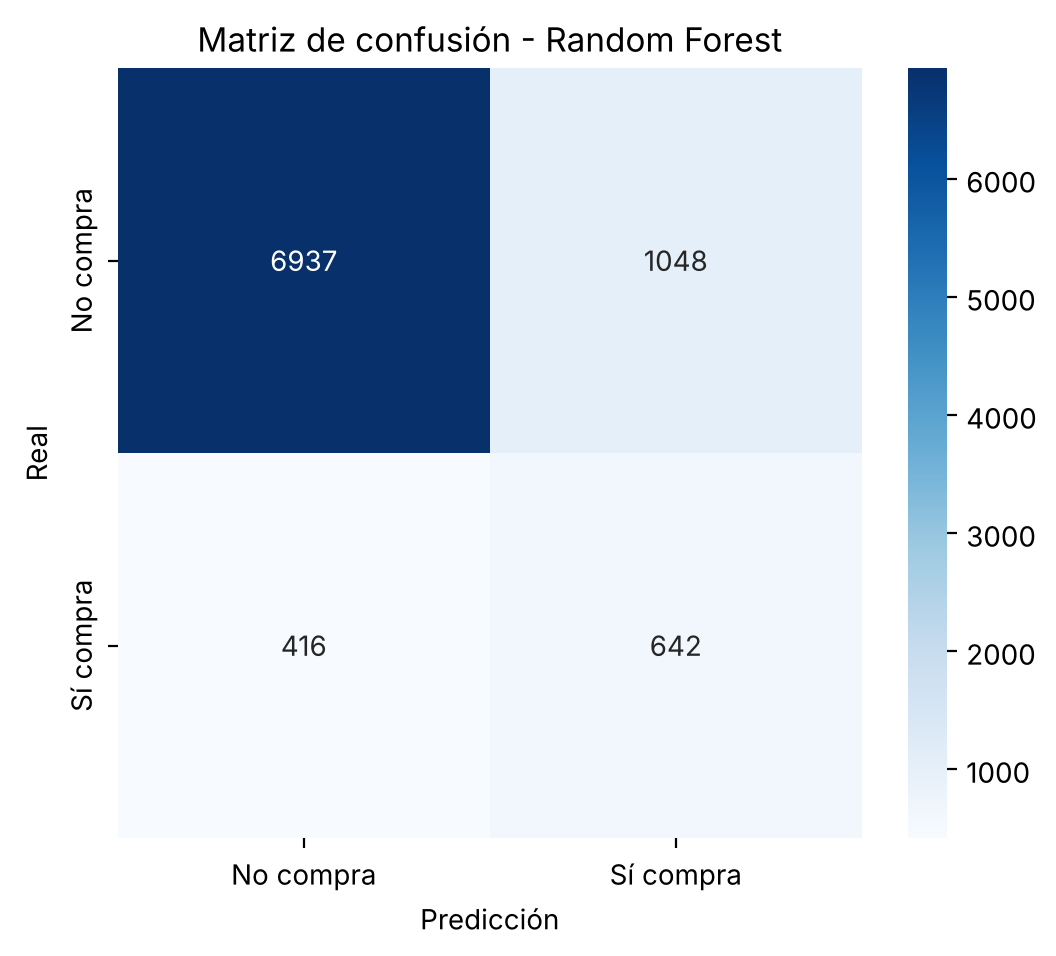

In [16]:
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No compra', 'Sí compra'],
            yticklabels=['No compra', 'Sí compra'])
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de confusión - Random Forest')
plt.show()

### 6.3 ¿Qué variables pesan más?

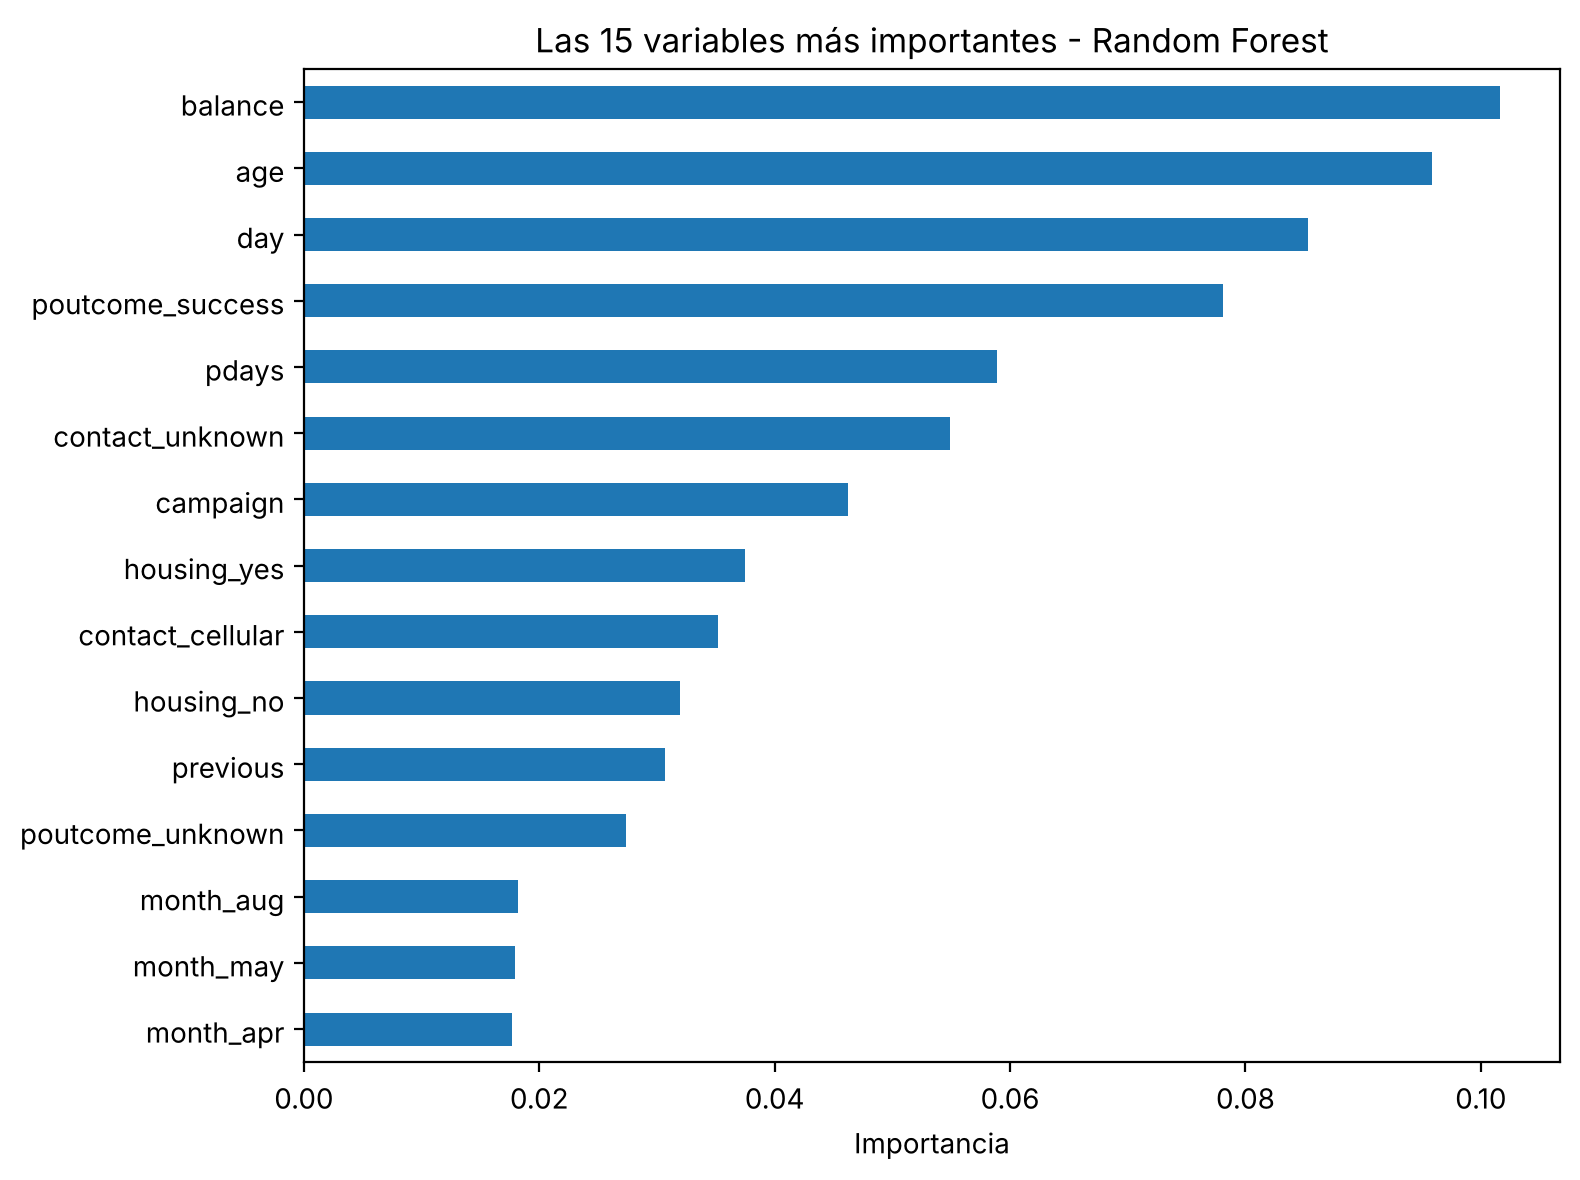

In [17]:
importancias = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
importancias.head(15).sort_values().plot(kind='barh')
plt.title('Las 15 variables más importantes - Random Forest')
plt.xlabel('Importancia')
plt.tight_layout()
plt.show()

## 7. Modelo 2: Red Neuronal Artificial (ANN) con Keras

Misma estructura vista en clase (`ANN_1`): capas `Dense` con activación `relu`, `Dropout` para
evitar sobreajuste y una neurona de salida.

Diferencias con el ejercicio de Fashion-MNIST:
- Aquí hay **2 clases**, no 10. Entonces la salida es **1 neurona con `sigmoid`** (da una
  probabilidad entre 0 y 1) y la pérdida es `binary_crossentropy`.
- Los datos son una tabla, no imágenes, así que no hace falta `Flatten` ni CNN.
- **Hay que escalar** con `StandardScaler` (la red, igual que el SVM, es sensible a la escala:
  `balance` llega a miles y las columnas One-Hot son 0 o 1). El scaler se ajusta solo con el train.
- `EarlyStopping`: detiene el entrenamiento cuando la pérdida de validación deja de mejorar.

In [18]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Mismo truco del desbalance que en Random Forest, pero para Keras
peso_no = len(y_train) / (2 * (y_train == 0).sum())
peso_si = len(y_train) / (2 * (y_train == 1).sum())
pesos_clase = {0: peso_no, 1: peso_si}
print('Pesos de clase:', {k: round(v, 3) for k, v in pesos_clase.items()})

Pesos de clase: {0: np.float64(0.566), 1: np.float64(4.274)}


In [19]:
ann = keras.Sequential([
    layers.Input(shape=(X_train_s.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')   # probabilidad de que compre
])

ann.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,377 (21.00 KB)

 Trainable params: 5,377 (21.00 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
parada_temprana = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True
)

hora_inicio = time()
history = ann.fit(
    X_train_s, y_train,
    epochs=50,
    batch_size=256,
    validation_split=0.2,
    class_weight=pesos_clase,
    callbacks=[parada_temprana],
    verbose=0
)
print('Tiempo de entrenamiento:', round(time() - hora_inicio, 1), 'segundos')
print('Épocas entrenadas:', len(history.history['loss']))

Tiempo de entrenamiento: 8.5 segundos
Épocas entrenadas: 18


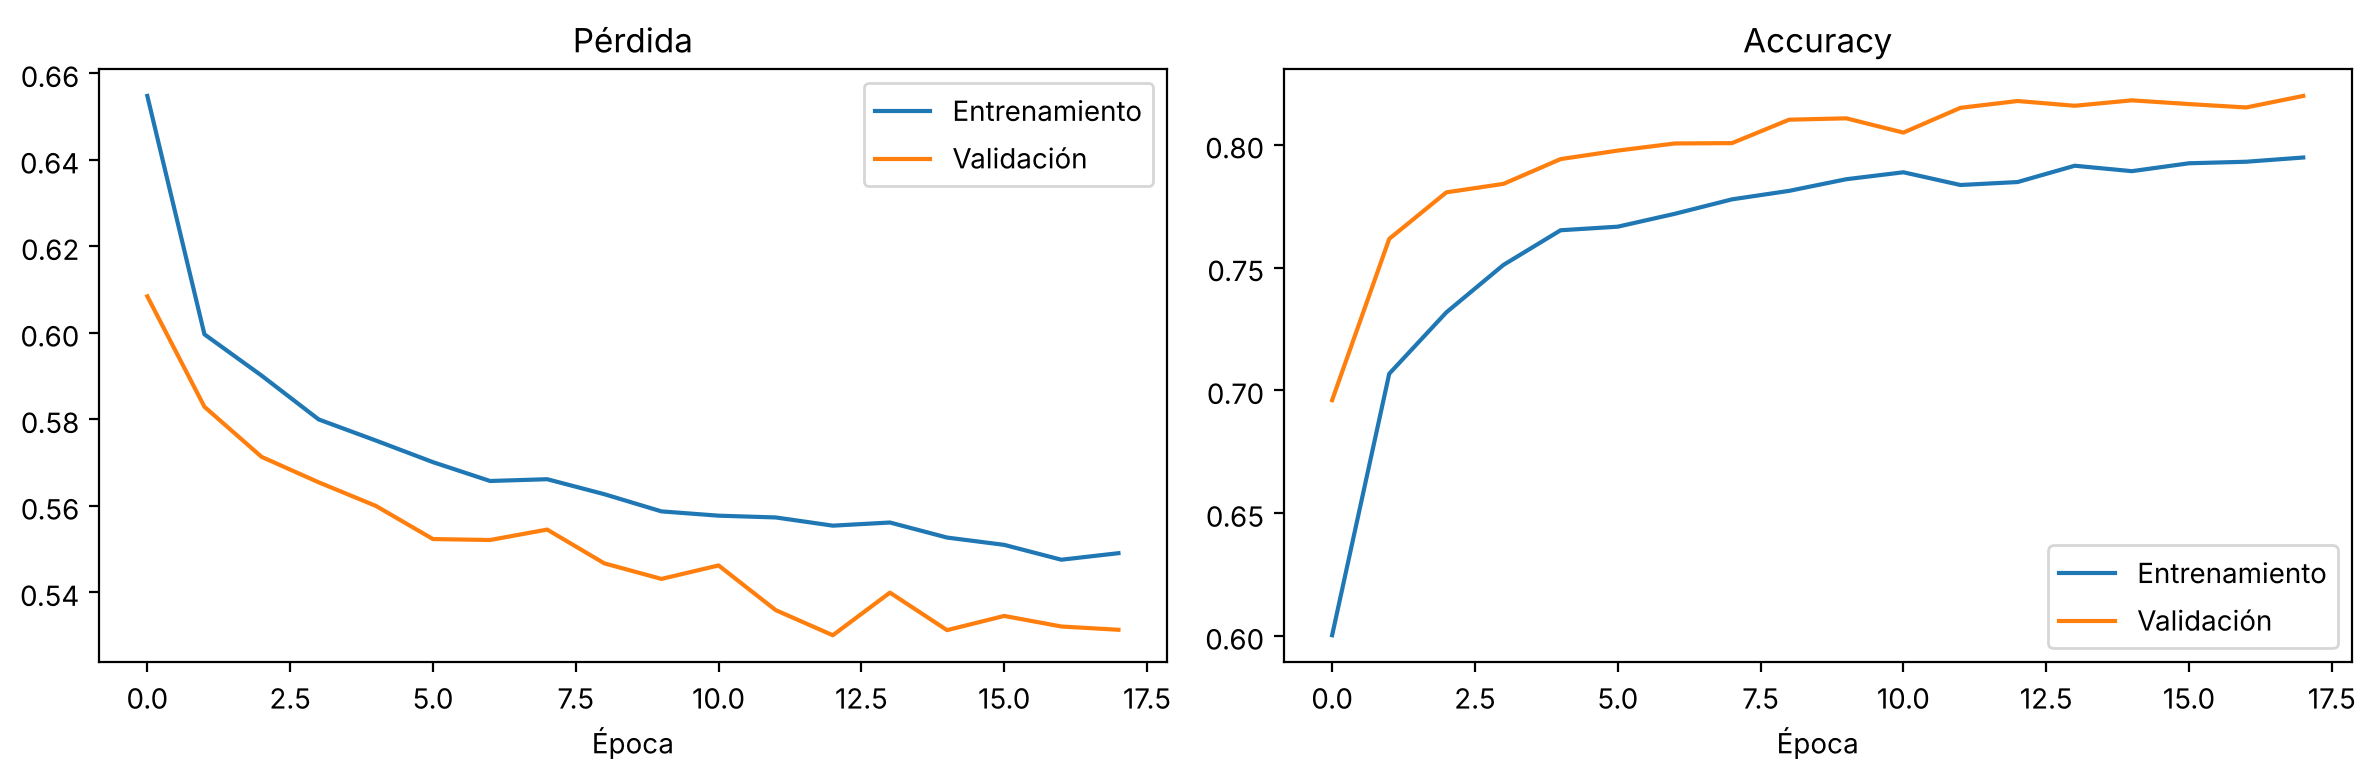

In [21]:
# Curvas de pérdida y accuracy (entrenamiento vs validación)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validación')
plt.title('Pérdida')
plt.xlabel('Época')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validación')
plt.title('Accuracy')
plt.xlabel('Época')
plt.legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

   No compra       0.94      0.85      0.89      7985
   Sí compra       0.35      0.60      0.44      1058

    accuracy                           0.82      9043
   macro avg       0.64      0.72      0.67      9043
weighted avg       0.87      0.82      0.84      9043



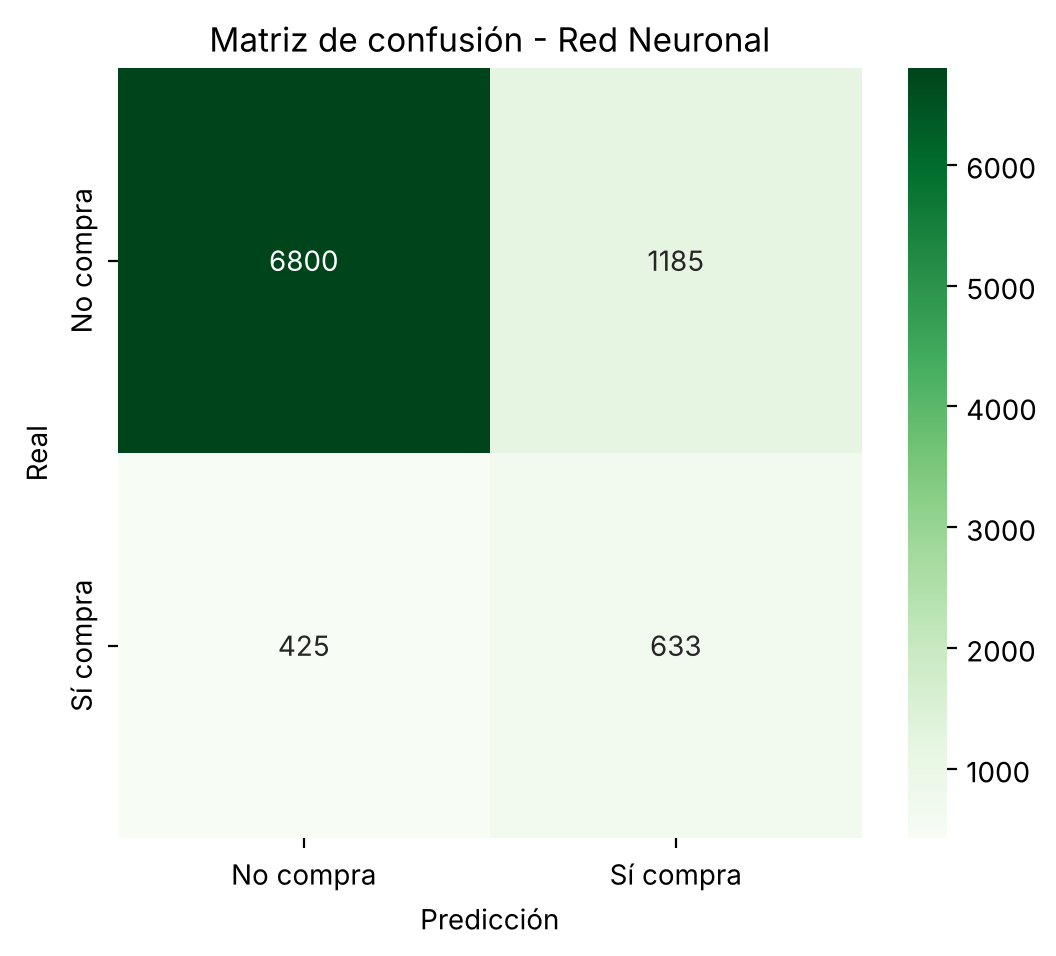

In [22]:
y_prob_ann = ann.predict(X_test_s, verbose=0).ravel()
y_pred_ann = (y_prob_ann >= 0.5).astype(int)

print(classification_report(y_test, y_pred_ann, target_names=['No compra', 'Sí compra']))

cm = confusion_matrix(y_test, y_pred_ann)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['No compra', 'Sí compra'],
            yticklabels=['No compra', 'Sí compra'])
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de confusión - Red Neuronal')
plt.show()

## 8. Comparación de modelos

In [23]:
def metricas(nombre, y_real, y_pred):
    return {
        'Modelo': nombre,
        'Accuracy': round(accuracy_score(y_real, y_pred), 4),
        'Precision (sí compra)': round(precision_score(y_real, y_pred, zero_division=0), 4),
        'Recall (sí compra)': round(recall_score(y_real, y_pred), 4),
        'F1 (sí compra)': round(f1_score(y_real, y_pred), 4),
    }

comparacion = pd.DataFrame([
    metricas('Línea base (siempre NO)', y_test, y_pred_base),
    metricas('Random Forest', y_test, y_pred_rf),
    metricas('Red neuronal (ANN)', y_test, y_pred_ann),
])
comparacion

,Modelo,Accuracy,Precision (sí compra),Recall (sí compra),F1 (sí compra)
0,Línea base (siempre NO),0.8830,0.0000,0.0000,0.0000
1,Random Forest,0.8381,0.3799,0.6068,0.4672
2,Red neuronal (ANN),0.8220,0.3482,0.5983,0.4402


**Cómo leer la tabla (en lenguaje de ventas):**
- **Recall:** de todos los clientes que de verdad compraron, ¿a cuántos detectó el modelo?
- **Precision:** de todos los clientes que el modelo marcó como "va a comprar", ¿cuántos compraron de verdad?
- **F1:** equilibrio entre las dos.

## 9. ¿Sirve en la práctica? Priorizar la lista de llamadas

La idea real para un vendedor no es un "sí/no", sino **ordenar a quién llamar primero**.
Ordenamos los clientes del test de mayor a menor probabilidad de compra y miramos cuántos
compradores hay en el 10% de arriba de la lista, comparado con llamar al azar.

In [24]:
mejor_prob = y_prob_rf   # se cambia si la ANN resulta mejor
orden = np.argsort(-mejor_prob)
top = int(len(y_test) * 0.10)

tasa_top = y_test.values[orden[:top]].mean()
tasa_azar = y_test.mean()
print(f'Llamando al azar: {round(tasa_azar * 100, 1)}% de las llamadas terminan en venta')
print(f'Llamando primero al 10% que el modelo marca: {round(tasa_top * 100, 1)}% terminan en venta')
print(f'Es decir, {round(tasa_top / tasa_azar, 1)} veces más efectivo que llamar al azar')

Llamando al azar: 11.7% de las llamadas terminan en venta
Llamando primero al 10% que el modelo marca: 50.3% terminan en venta
Es decir, 4.3 veces más efectivo que llamar al azar


## 10. Guardar el modelo para la página web

Guardamos:
1. El modelo entrenado.
2. La lista exacta de columnas después del One-Hot, para que la página web construya los datos
   del cliente **con el mismo preprocesamiento** que se usó al entrenar (como se exigía en el
   parcial del segundo corte).
3. Los puntajes del conjunto de prueba con su resultado real. Como el puntaje no es una
   probabilidad real (por el `class_weight`), la página compara al cliente nuevo contra estos
   clientes de prueba: en qué lugar de la lista queda y cuántos de los clientes con un puntaje
   igual o mayor compraron de verdad.

In [25]:
joblib.dump(rf, 'modelo_rf.joblib', compress=3)   # comprimido para que pese menos
joblib.dump(list(X.columns), 'columnas.joblib')
joblib.dump({'puntajes': y_prob_rf, 'compro': y_test.values}, 'referencia_test.joblib')
print('Modelo guardado')

Modelo guardado
